In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pickle as pickle
import os
import import_ipynb
from matplotlib.patches import FancyArrowPatch
import ipynb.fs.full.ssiProjectModule as ssiMod
import importlib as imp
imp.reload(ssiMod)
import itertools
from matplotlib.collections import LineCollection as LC


In [2]:
def SETUP_FIGURE(fwidth, fheight):

    fig = plt.figure(figsize=(fwidth, fheight))

    left_margin  = 0.2 / fwidth
    right_margin = 0.2 / fwidth
    bottom_margin = 0.2 / fheight
    top_margin = 0.2 / fheight

    #---- create axes ----

    # dimensions are calculated relative to the figure size

    x = left_margin    # horiz. position of bottom-left corner
    y = bottom_margin  # vert. position of bottom-left corner
    w = 1 - (left_margin + right_margin) # width of axes
    h = 1 - (bottom_margin + top_margin) # height of axes

    ax = fig.add_axes([x, y, w, h])

    for axis in ['bottom','left']:
        ax.spines[axis].set_linewidth(1)
    ax.xaxis.set_tick_params(width=1)
    ax.yaxis.set_tick_params(width=1)
    #---- Define the Ylabel position ----

    # Location are defined in dimension relative to the figure size  

    xloc =  0.25 / fwidth 
    yloc =  y + h / 2.  
         
#     ax.yaxis.set_label_coords(xloc, yloc, transform = fig.transFigure)
    return fig,ax

In [3]:
theta_step = 2

exp_dir = 'C:/Users/Carlo PARIS/00PhD Code/CoSyne/'

main_dir = 'C:/Users/Carlo PARIS/00PhD Code/'
dat_dir_in = 'C:/Users/Carlo PARIS/00PhD Code/0Paper plots/Figure1/'
dat_dir_out = 'C:/Users/Carlo PARIS/00PhD Code/0Paper plots/Figure3/'
title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'

with open(dat_dir_in+title, 'rb') as rick:
    data_dict = pickle.load(rick)
bio_idx = np.where(data_dict['all_multipliers']==1.)[0][0]
print(data_dict.keys())

dict_keys(['all_multipliers', 'all_quad_pars', 'all_quad_tc', 'all_ssis', 'all_quad_fwhm', 'exp_quad_list', 'all_quad_vm_fit_pars', 'all_quad_raw_mean_tcs', 'all_quad_raw_mean_stds', 'original_cell_idx_quads'])


In [125]:
colors=['blue', 'green','red', 'gold' ]
example_quads = [125,201]
cm = 1/2.54
page_unit_width = 3*(16*cm)/20
stim180 = np.arange(0,360,2)

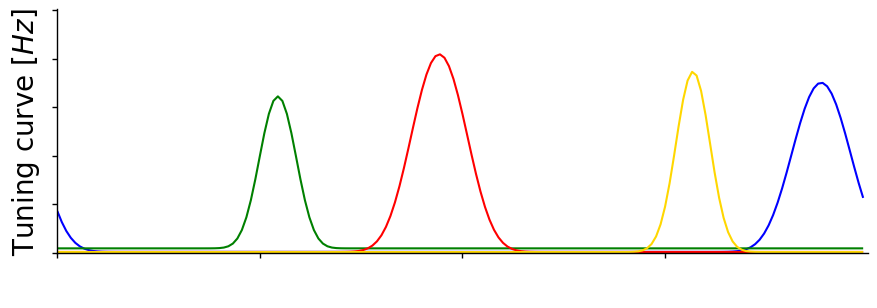

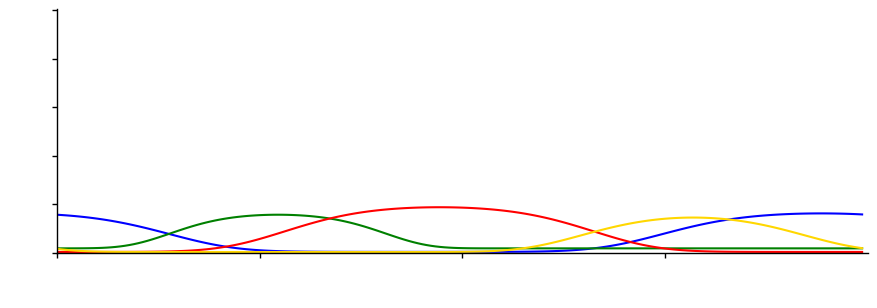

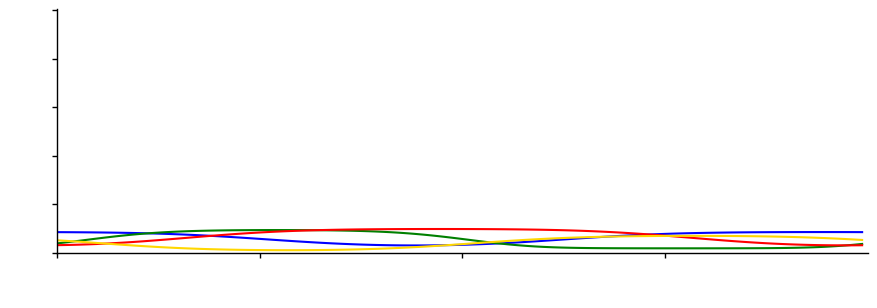

In [157]:
example_tc = data_dict['all_quad_tc'][example_quads[1]]/1.6

chosen_idxs = [2, bio_idx, -2]

for idx, i in enumerate(chosen_idxs):
    fig, ax = SETUP_FIGURE(9*page_unit_width,3*page_unit_width)
    lc = LC(np.concatenate((np.tile(np.copy(stim)[None,:,None], (4,1,1)),np.copy(example_tc[i])[:,:,None]), axis=2), \
                colors = colors)

    ax.set_xticks(np.arange(0,360, 90), [])
    ymax = (example_tc[chosen_idxs].max()//50+1)*50+1
    
    ax.set_yticks(np.arange(0,ymax, 50), [])
    ax.set_xlim(0,360)
    ax.set_ylim(0,ymax)
    ax.set_xlabel(r'Direction of motion [$\degree]$', color = 'white',size = 20)

    if idx==0:
        ax.set_ylabel(r'Tuning curve [$Hz$]', color = 'black',size = 20)
    else:
        ax.set_ylabel(r'Tuning curve [$Hz$]', color = 'white',size = 20)
    
    ax.add_collection(lc)
    fig.savefig(dat_dir_out+f'tc_quad{example_quads[1]}_idx{i}.png', dpi = 300, bbox_inches = 'tight')  

(3, 4, 180)
(56, 180)


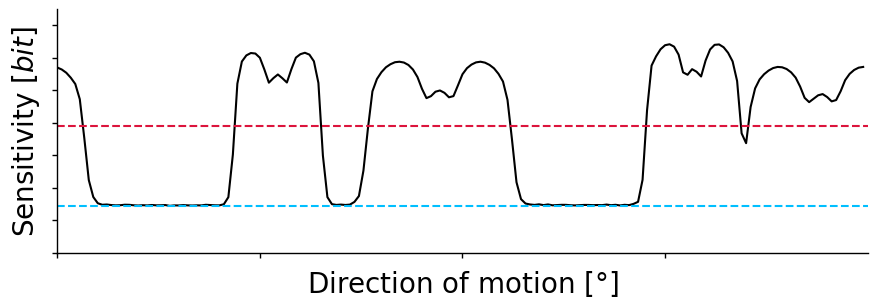

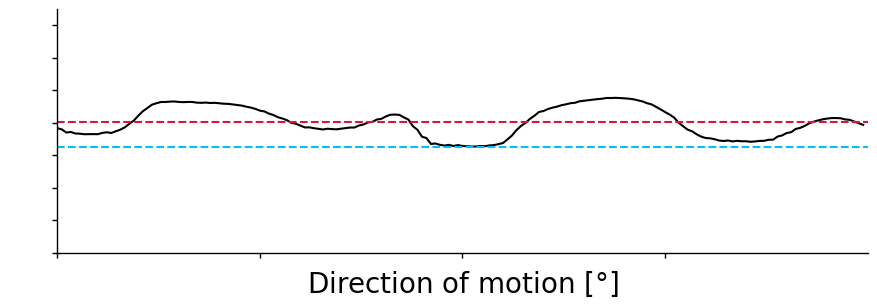

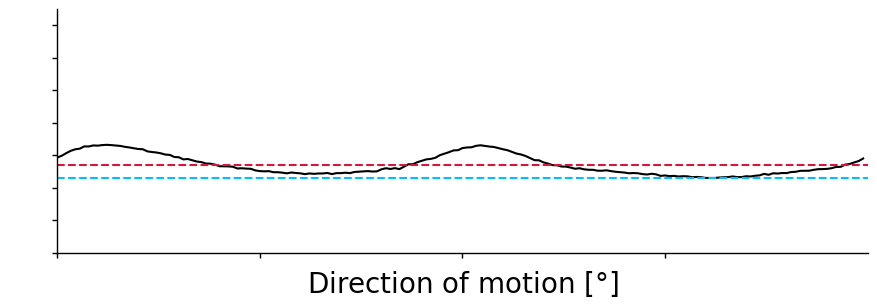

In [155]:
chosen_idxs = [2, bio_idx, -2]

example_four_ssi = np.array([ssiMod.GET_SSI_LOOP(quad_tc) for quad_tc in \
                             data_dict['all_quad_tc'][example_quads[1],chosen_idxs]])
print(example_four_ssi.shape)
example_ssis = data_dict['all_ssis'][example_quads[1]]
print(example_ssis.shape)

for ssi_idx, i in enumerate(chosen_idxs):

    fig, ax = SETUP_FIGURE(9*page_unit_width,3*page_unit_width)
#     lc = LC(np.concatenate((np.tile(np.copy(stim180)[None,:,None], (4,1,1)), np.copy(example_four_ssi[ssi_idx])[:,:,None]), axis=2), \
#                 colors = colors)
#     ax.add_collection(lc)    
    ax.plot(stim180, example_ssis[i], color = 'k')
    ax.axhline(example_ssis[i].mean(), linestyle = 'dashed', color = 'crimson')
    ax.axhline(example_ssis[i].min(), linestyle = 'dashed', color = 'deepskyblue')
    
    ax.set_xticks(np.arange(0,360, 90), [])
    ymax = 7.5
    ax.set_yticks(np.arange(0,ymax, 1), [])
    ax.set_xlabel(r'Direction of motion [$\degree]$', size = 20)
    if ssi_idx==0:
        ax.set_ylabel(r'Sensitivity [$bit$]', color = 'black',size = 20)
    else:
        ax.set_ylabel(r'Sensitivity [$bit$]', color = 'white',size = 20)    
    ax.set_xlim(0,360)
    ax.set_ylim(0,ymax)
    fig.savefig(dat_dir_out+f'ssi_quad{example_quads[1]}_idx{i}.png', dpi = 300, bbox_inches = 'tight')

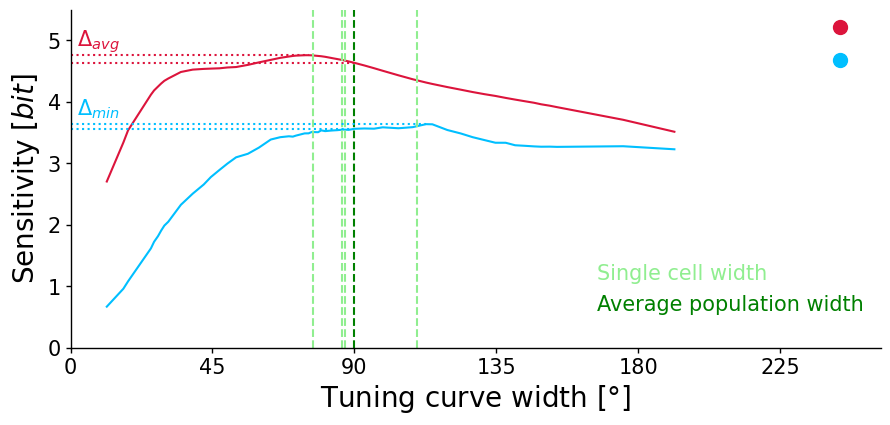

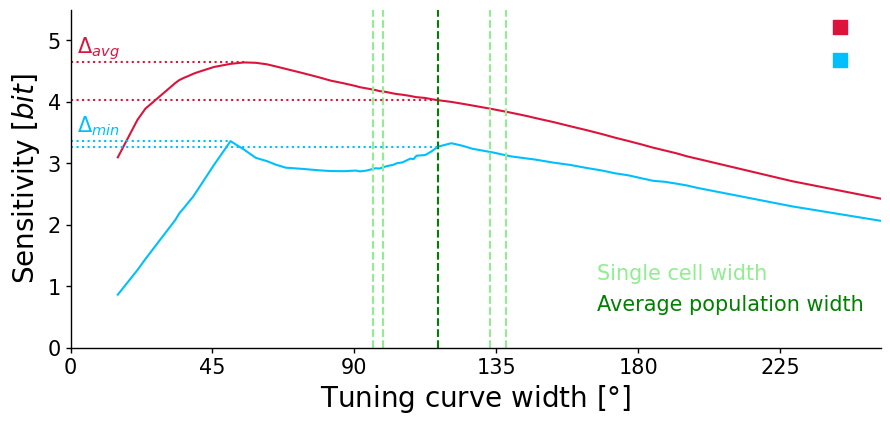

In [165]:
# example_quads = [300,100]


ssis = data_dict['all_ssis'][example_quads]
fwhms = data_dict['all_quad_fwhm'][example_quads]

scatter_marker = ['o', 's']

for i,el in enumerate(example_quads):
    ymax = 5.5
    bio_fwhm_mean = fwhms[i].mean(axis=1)[bio_idx]
    bio_fwhm_std = fwhms[i].std(axis=1)[bio_idx]
    
    
    fig, ax = SETUP_FIGURE(9*page_unit_width, 4*page_unit_width)
    ax.plot(fwhms[i].mean(axis=1), ssis[i].mean(axis=1), color = 'crimson')
    ax.plot(fwhms[i].mean(axis=1), ssis[i].min(axis=1), color = 'deepskyblue')   
    ax.axvline(fwhms[i].mean(axis=1)[bio_idx], linestyle = 'dashed', color = 'green')
    
    for fwhm in fwhms[i,bio_idx]:
        ax.axvline(fwhm, linestyle = 'dashed', color = 'lightgreen')
#     ax.fill_between([bio_fwhm_mean-bio_fwhm_std, bio_fwhm_mean+bio_fwhm_std], \
#                     [0,0], [ymax,ymax],linestyle = 'dashed', color = 'green', alpha = 0.2)
    
    ax.axhline(ssis[i].mean(axis=1).max(), 0, \
               fwhms[i].mean(axis=1)[ssis[i].mean(axis=1).argmax()]/fwhms.mean(axis=2).max(), \
               linestyle = 'dotted', color = 'crimson')
    ax.axhline(ssis[i].mean(axis=1)[bio_idx], 0, \
               fwhms[i].mean(axis=1)[bio_idx]/fwhms.mean(axis=2).max(), \
               linestyle = 'dotted', color = 'crimson')
    
    ax.axhline(ssis[i].min(axis=1).max(), 0, \
               fwhms[i].mean(axis=1)[ssis[i].min(axis=1).argmax()]/fwhms.mean(axis=2).max(), \
               linestyle = 'dotted', color = 'deepskyblue')
    ax.axhline(ssis[i].min(axis=1)[bio_idx], 0, \
               fwhms[i].mean(axis=1)[bio_idx]/fwhms.mean(axis=2).max(), \
               linestyle = 'dotted', color = 'deepskyblue')
    ax.text(2, ssis[i].mean(axis=1).max()+0.15, r'$\Delta_{avg}$', color = 'crimson', size = 15)
    ax.text(2, ssis[i].min(axis=1).max()+0.15, r'$\Delta_{min}$', color = 'deepskyblue', size = 15)
    
    
    ax.tick_params(labelsize = 15)
    ax.set_xticks(np.arange(0,fwhms.mean(axis=2).max(), 45))
    ax.set_yticks(np.arange(0,ymax, 1))
    ax.set_xlim(0,fwhms.mean(axis=2).max())
    ax.set_ylim(0,ymax)
    ax.set_xlabel(r'Tuning curve width [$\degree$]', size = 20)
    ax.set_ylabel(r'Sensitivity [$bit$]', size = 20)
    
    ax.scatter(0.95*fwhms.mean(axis=2).max(), 0.95*ymax, marker = scatter_marker[i], color = 'crimson', s=100)
    ax.scatter(0.95*fwhms.mean(axis=2).max(), 0.85*ymax, marker = scatter_marker[i], color = 'deepskyblue', s=100)
    
    ax.text(0.65, 0.2, 'Single cell width', color = 'lightgreen', size = 15, transform = ax.transAxes)
    ax.text(0.65, 0.11, 'Average population width', color = 'green', size = 15, transform = ax.transAxes)
    
    
    fig.savefig(dat_dir_out+f'fwhm_vs_Avg&MinSSI_quad{el}.png', dpi = 300, bbox_inches = 'tight')

In [6]:
maxmin_width_idx = data_dict['all_ssis'].min(axis = 2).argmax(axis=1)
maxMin_widths = np.array([np.mean([ssiMod.FWHM(pars)[1] for pars in data_dict['all_quad_pars'][i,el]]) \
                           for i, el in enumerate(maxmin_width_idx)])
  
maxAvg_width_idx = data_dict['all_ssis'].mean(axis = 2).argmax(axis=1)
maxAvg_widths = np.array([np.mean([ssiMod.FWHM(pars)[1] for pars in data_dict['all_quad_pars'][i,el]]) \
                           for i, el in enumerate(maxAvg_width_idx)])

(648,)
(array([87., 67., 47., 43., 44., 39., 44., 28., 23., 29., 17., 14., 17.,
       22., 24., 12., 18., 15.,  9., 11.,  9., 10.,  3.,  2.,  6.,  6.,
        0.,  0.,  1.,  1.]), array([0.        , 0.03112713, 0.06225426, 0.09338139, 0.12450852,
       0.15563565, 0.18676278, 0.21788991, 0.24901704, 0.28014417,
       0.3112713 , 0.34239843, 0.37352557, 0.4046527 , 0.43577983,
       0.46690696, 0.49803409, 0.52916122, 0.56028835, 0.59141548,
       0.62254261, 0.65366974, 0.68479687, 0.715924  , 0.74705113,
       0.77817826, 0.80930539, 0.84043252, 0.87155965, 0.90268678,
       0.93381391]), [<matplotlib.patches.Polygon object at 0x000001E9AF7095E0>]) (array([ 2.,  3.,  3., 15., 18., 35., 35., 32., 34., 33., 33., 24., 49.,
       34., 37., 41., 37., 41., 33., 24., 21., 19.,  9., 10.,  9.,  5.,
        3.,  4.,  2.,  3.]), array([0.02599534, 0.05679082, 0.0875863 , 0.11838178, 0.14917726,
       0.17997273, 0.21076821, 0.24156369, 0.27235917, 0.30315465,
       0.33395013, 0.364745

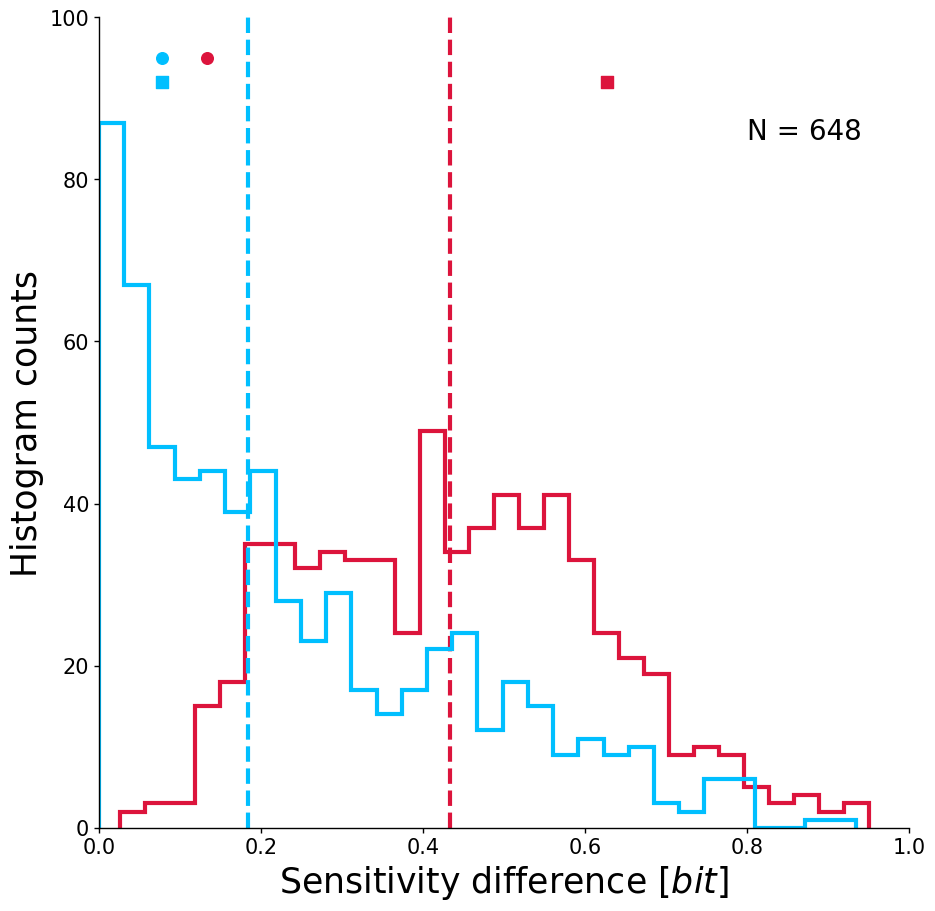

In [139]:
scatter_marker = ['o', 's']

print(maxAvg_width_idx.shape)
maxAvg_vals = np.array([evol[maxAvg_width_idx[i]] for i, evol in enumerate(data_dict['all_ssis'].mean(axis=2))])
maxMin_vals = np.array([evol[maxmin_width_idx[i]] for i, evol in enumerate(data_dict['all_ssis'].min(axis=2))])

maxAvg_loss = (maxAvg_vals-data_dict['all_ssis'].mean(axis=2)[:,bio_idx])#/data_dict['all_ssis'].mean(axis=2)[:,bio_idx]*100
maxMin_loss = (maxMin_vals-data_dict['all_ssis'].min(axis=2)[:,bio_idx])#/data_dict['all_ssis'].min(axis=2)[:,bio_idx]*100

fig, ax = SETUP_FIGURE(9*page_unit_width, 9*page_unit_width)

avg_histx = ax.hist(maxAvg_loss, bins = 30, linewidth = 3, histtype = 'step', color = 'crimson')
ax.axvline(np.median(maxAvg_loss), 0, 100, linewidth = 3, linestyle = 'dashed', color = 'crimson')

min_histx = ax.hist(maxMin_loss, bins = 30, linewidth = 3, histtype = 'step', color = 'deepskyblue')
ax.axvline(np.median(maxMin_loss), 0, 100, linewidth = 3, linestyle = 'dashed', color = 'deepskyblue')

ax.text(0.8, 0.85, r'N = 648', fontsize = 20, color = 'k', transform = ax.transAxes)

ax.tick_params(labelsize = 15)
ax.set_xticks(np.arange(0,1.1,0.2))
ax.set_yticks(np.arange(0,101,20))

ax.set_xlim(0,1)
ax.set_ylim(0,100)

ax.set_xlabel(r'Sensitivity difference [$bit$]', size = 25)
ax.set_ylabel(r'Histogram counts', size = 25)

decreaseMin = 0

print(min_histx, avg_histx)

for i,el in enumerate(example_quads):
    print(el)
    print(np.where(maxMin_loss[el]<=min_histx[1])[0][0])
    print(np.where(maxAvg_loss[el]<=avg_histx[1])[0][0])
    
    
    ax.scatter((min_histx[1][np.where(maxMin_loss[el]<=min_histx[1])[0][0]]+\
                min_histx[1][np.where(maxMin_loss[el]<=min_histx[1])[0][0]-1])/2, 95-decreaseMin,\
              marker = scatter_marker[i], color = 'deepskyblue', s= 70)
    
    ax.scatter((avg_histx[1][np.where(maxAvg_loss[el]<=avg_histx[1])[0][0]]+\
                avg_histx[1][np.where(maxAvg_loss[el]<=avg_histx[1])[0][0]-1])/2, 95-decreaseMin,\
              marker = scatter_marker[i], color = 'crimson', s= 70)

    decreaseMin += 3

print(min_hist)
fig.savefig(dat_dir_out+'Loss_histogram.png', dpi = 300, bbox_inches = 'tight')